# Phân tích dữ liệu

In [2]:
import numpy as np
import struct
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

import torch
import torch.nn as nn
import torch.optim as optim

import tensorflow as tf

In [3]:
def load_images(path):
    with open(path, "rb") as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))

        data = np.frombuffer(
            f.read(),
            dtype=np.uint8
        )

    images = data.reshape(num_images, rows, cols)

    return images

In [4]:
def load_labels(path):
    with open(path, "rb") as f:
        magic, num_labels = struct.unpack(">II", f.read(8))

        labels = np.frombuffer(
            f.read(),
            dtype=np.uint8
        )

    return labels

In [6]:
X_train = load_images("C:/DATA/MNIST/train-images.idx3-ubyte")
y_train = load_labels("C:/DATA/MNIST/train-labels.idx1-ubyte")

X_test = load_images("C:/DATA/MNIST/t10k-images.idx3-ubyte")
y_test = load_labels("C:/DATA/MNIST/t10k-labels.idx1-ubyte")

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


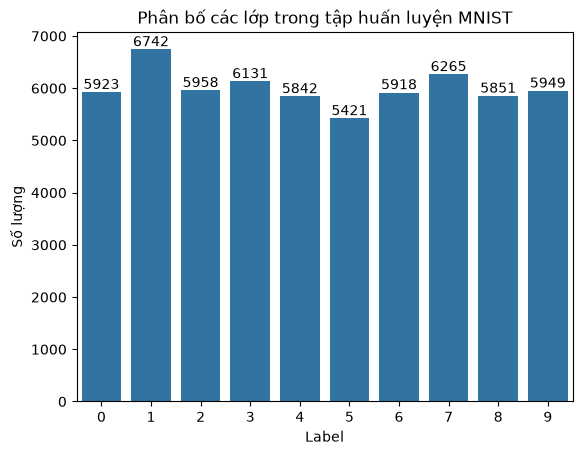

In [7]:
ax = sns.countplot(x=y_train)

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.title("Phân bố các lớp trong tập huấn luyện MNIST")
plt.show()

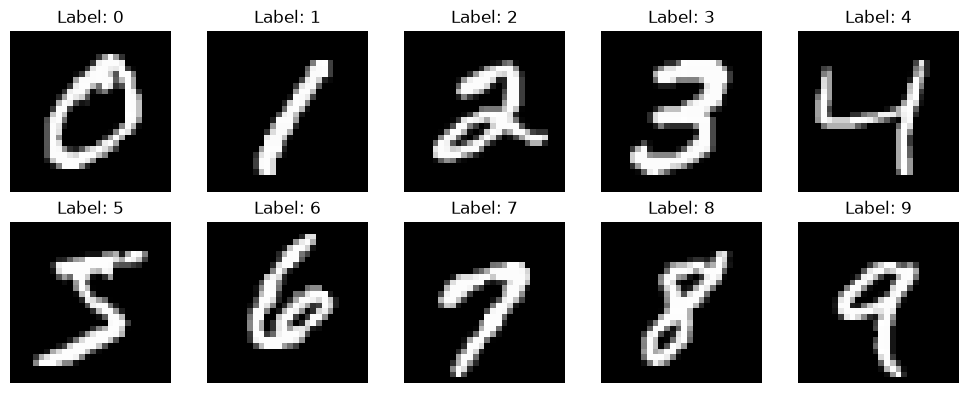

In [8]:
plt.figure(figsize=(10, 4))

for i in range(10):
    idx = np.where(y_train == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[idx], cmap="gray")
    plt.title(f"Label: {y_train[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Chuẩn hóa

In [9]:
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

In [10]:
X_train = X_train[:, :, :, np.newaxis]
X_test = X_test[:, :, :, np.newaxis]

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


# Huấn luyện

In [11]:
def drawLvsE(losses):
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training Loss")
    plt.show()

## CNN From Scratch

In [12]:
joblib.dump(
    [X_train, y_train, X_test, y_test], "mnist_data.pkl"
)

['mnist_data.pkl']

In [13]:
stop =
#Cell ngăn cách
# khi chạy xong file train_cnn.ipynb
# thì chạy tiếp từ cell bên dưới

SyntaxError: invalid syntax (860721852.py, line 1)

In [14]:
cnn_res = joblib.load("cnn_result.pkl")

## CNN PyTorch

In [15]:
# Chuyển về tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

X_train_t = X_train_t.permute(0, 3, 1, 2)
X_test_t = X_test_t.permute(0, 3, 1, 2)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print(X_train_t.shape, X_test_t.shape)
print(y_train_t.shape, y_test_t.shape)

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])
torch.Size([60000]) torch.Size([10000])


In [16]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Conv 1
        self.conv1 = nn.Conv2d(1, 8, 3)

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Conv 2
        self.conv2 = nn.Conv2d(8, 8, 3)

        # Fully Connected
        self.fc1 = nn.Linear(8 * 5 * 5, 16)

        self.fc2 = nn.Linear(16, 10)

    def forward(self, x):

        # Conv 1 → ReLU → Pool
        x = self.conv1(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Conv 2 → ReLU → Pool
        x = self.conv2(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0),-1)

        # Dense
        x = self.fc1(x)
        x = torch.relu(x)

        # Output
        x = self.fc2(x)

        return x

In [17]:
model = CNN()

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

In [18]:
epochs = 10
batch_size = 32

losses = []

for epoch in range(epochs):

    permutation = torch.randperm(
        X_train_t.size(0)
    )

    total_loss = 0
    num_batches = 0

    for i in range(0, X_train_t.size(0), batch_size):

        idx = permutation[i:i + batch_size]

        X_batch = X_train_t[idx]
        y_batch = y_train_t[idx]

        optimizer.zero_grad()

        y_hat = model(X_batch)

        loss = criterion(
            y_hat,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    avg_loss = total_loss / num_batches

    losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Loss: {avg_loss:.4f}"
    )

Epoch 1/10 - Loss: 1.2037
Epoch 2/10 - Loss: 0.3352
Epoch 3/10 - Loss: 0.2273
Epoch 4/10 - Loss: 0.1686
Epoch 5/10 - Loss: 0.1425
Epoch 6/10 - Loss: 0.1279
Epoch 7/10 - Loss: 0.1169
Epoch 8/10 - Loss: 0.1090
Epoch 9/10 - Loss: 0.1036
Epoch 10/10 - Loss: 0.0978


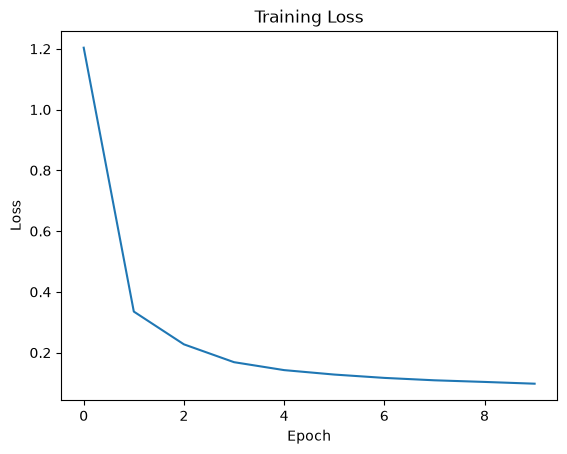

In [19]:
drawLvsE(losses)

## CNN TensorFlow

In [20]:
nf, mf, c = X_train.shape[1:]

In [21]:
cnn_tf = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(nf, mf, c)),
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(c),
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(c),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_tf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        73,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,578 (291.32 KB)

 Trainable params: 74,578 (291.32 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
cnn_tf.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
history_cnn = cnn_tf.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8708 - loss: 0.4352
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9401 - loss: 0.2068
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9586 - loss: 0.1440
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9666 - loss: 0.1132
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9718 - loss: 0.0961
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9758 - loss: 0.0839
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9779 - loss: 0.0746
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9802 - loss: 0.0673
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9817 - loss: 0.0614
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9829 - loss: 0.0568


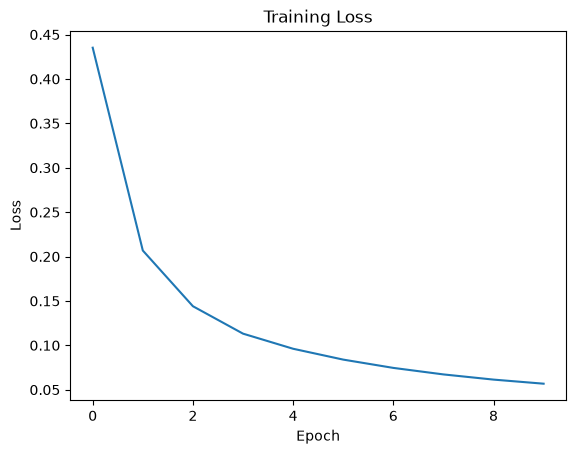

In [24]:
drawLvsE(history_cnn.history["loss"])

# Kết quả

In [29]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

def evaluation(name, y_test, y_prob):
    y_pred = np.argmax(y_prob, axis=1)

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    return {
        'Model': name,
        'Accuracy': acc, 'Precision': precision,
        'Recall': recall, 'F1-score': f1,
        'Confusion Matrix': cm
    }

In [30]:
res = []
# CNN from scratch
res.append(cnn_res)

# CNN PyTorch
with torch.no_grad():
    y_prob = model(X_test_t)
y_prob = y_prob.numpy()
res.append(evaluation("CNN PyTorch", y_test, y_prob))

#CNN TensorFlow
y_prob = cnn_tf.predict(X_test,verbose=0)
res.append(evaluation("CNN TensorFlow", y_test, y_prob))

In [32]:
import pandas as pd

res_df = pd.DataFrame(res).set_index('Model')

metric_df = res_df.drop(columns = ['Confusion Matrix'])

metric_df.sort_values(
    by='Accuracy',
    ascending=False
)

,Accuracy,Precision,Recall,F1-score
Model,,,,
CNN TensorFlow,0.9812,0.981397,0.9812,0.981194
CNN PyTorch,0.9753,0.975370,0.9753,0.975292
CNN From Scratch,0.0974,0.009740,0.1000,0.017751


In [33]:
for row in res:
    print(row['Model'])
    print(row['Confusion Matrix'])

CNN From Scratch
[[   0    0    0    0    0    0    0    0  980    0]
 [   0    0    0    0    0    0    0    0 1135    0]
 [   0    0    0    0    0    0    0    0 1032    0]
 [   0    0    0    0    0    0    0    0 1010    0]
 [   0    0    0    0    0    0    0    0  982    0]
 [   0    0    0    0    0    0    0    0  892    0]
 [   0    0    0    0    0    0    0    0  958    0]
 [   0    0    0    0    0    0    0    0 1028    0]
 [   0    0    0    0    0    0    0    0  974    0]
 [   0    0    0    0    0    0    0    0 1009    0]]
CNN PyTorch
[[ 966    0    2    0    2    2    2    1    3    2]
 [   0 1125    3    0    2    0    1    1    3    0]
 [   1    3 1008    2    3    0    0    9    6    0]
 [   1    0    5  967    0   19    0    8    8    2]
 [   1    0    3    1  970    0    1    2    2    2]
 [   2    1    0    9    0  868    5    3    3    1]
 [   5    3    2    0    4    6  935    0    3    0]
 [   1    2   12    3    1    0    0 1006    1    2]
 [   5    0    5

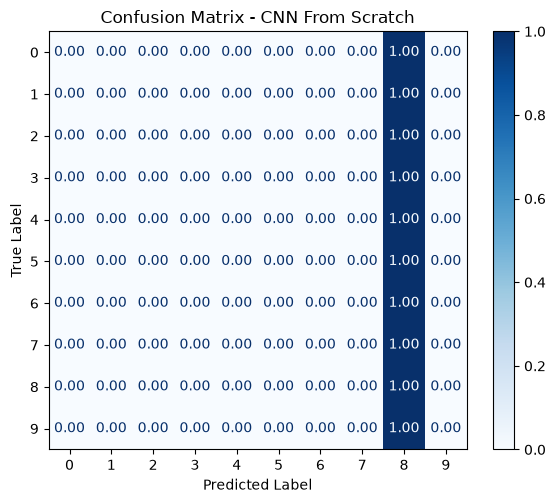

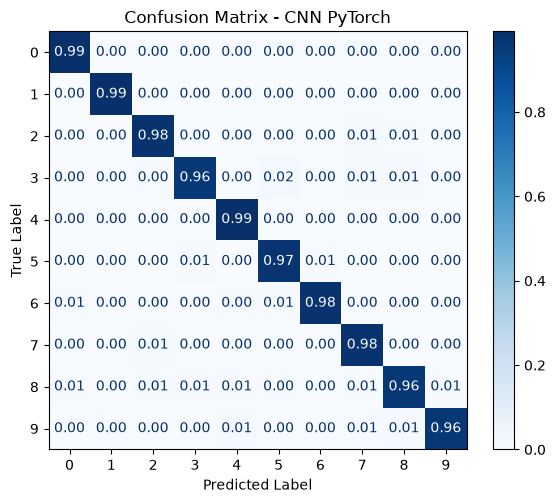

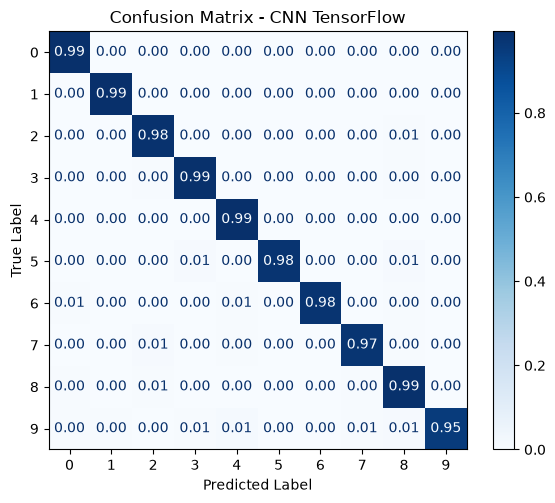

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for row in res:
    model_name = row['Model']
    cm = row['Confusion Matrix']

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_norm,
        display_labels=range(10)
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='.2f'
    )

    ax.set_title(f'Confusion Matrix - {model_name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

    plt.tight_layout()
    plt.show()

# Deploy

In [35]:
joblib.dump(
    cnn_tf,
    "mnist_deployment.pkl"
)

['mnist_deployment.pkl']